# Solutions to notebook 9: Time stepping and stability regions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/09_time_stepping_and_stability.ipynb)

Worked solutions to the exercises at the end of [notebook 9](../notebooks/09_time_stepping_and_stability.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# fft_derivative(v, order) from notebook 2
def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v; the Nyquist mode is zeroed for odd orders."""
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

# functions from notebook 9
R = {
    "forward Euler": lambda z: 1 + z,
    "midpoint RK2": lambda z: 1 + z + z**2 / 2,
    "RK4": lambda z: 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24,
}

def axis_limit(R_of_z, direction):
    """Distance from the origin to the edge of the stability region along the given direction."""
    return brentq(lambda s: abs(R_of_z(s * direction)) - 1, 0.5, 10)

def largest_stable_step(eigenvalues, R_of_z):
    """Largest Δt for which |R(λ Δt)| <= 1 for every eigenvalue λ (one-step formula with stability function R)."""
    excess = lambda dt: np.abs(R_of_z(dt * eigenvalues)).max() - 1 - 1e-9
    trial = np.geomspace(1e-8, 10, 4000)
    first_bad = np.argmax([excess(dt) > 0 for dt in trial])
    return brentq(excess, trial[first_bad - 1], trial[first_bad])

def rk4_step(f, u, dt):
    """One step of the classical fourth-order Runge-Kutta formula for u' = f(u)."""
    k1 = f(u)
    k2 = f(u + dt / 2 * k1)
    k3 = f(u + dt / 2 * k2)
    k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

## Exercise 1

The third-order Runge-Kutta formulas have $R(z) = 1 + z + \tfrac12 z^2 + \tfrac16 z^3$.
Compute how far the stability region extends along the negative real axis and along the
imaginary axis (exact value on the imaginary axis: $\sqrt3$). Add the region to the first
panel of the figure in 9.2. Per evaluation of the right-hand side, is RK3 or RK4 the more
economical choice for the advection problem of 9.5?

`axis_limit` finds where $|R| = 1$ along a ray from the origin. On the imaginary axis the value
can be found by hand: $|R(iy)|^2 = (1 - \tfrac12y^2)^2 + (y - \tfrac16y^3)^2
= 1 - \tfrac1{12}y^4 + \tfrac1{36}y^6$, which equals 1 at $y^2 = 3$. For the economy question,
the advection problem has imaginary eigenvalues, so the largest stable step is proportional to
the reach along the imaginary axis. A formula with $s$ stages costs $s$ evaluations per step,
and the figure of merit is the reach divided by $s$: the time advanced per evaluation.

RK3: stable for real z down to -2.5127, and for imaginary z up to ±1.7321 i   (√3 = 1.7321)
RK4: stable for real z down to -2.7853, and for imaginary z up to ±2.8284 i
imaginary reach per evaluation:  RK3 0.5774   RK4 0.7071   ratio 1.225


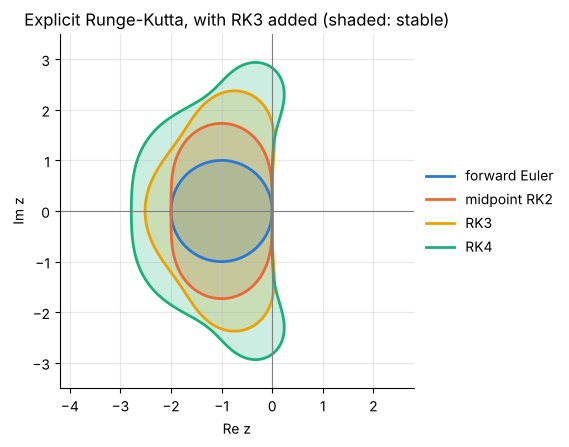

In [3]:
R["RK3"] = lambda z: 1 + z + z**2 / 2 + z**3 / 6
rk3_real, rk3_imag = axis_limit(R["RK3"], -1), axis_limit(R["RK3"], 1j)
rk4_real, rk4_imag = axis_limit(R["RK4"], -1), axis_limit(R["RK4"], 1j)
print(f"RK3: stable for real z down to -{rk3_real:.4f}, and for imaginary z up to ±{rk3_imag:.4f} i   (√3 = {np.sqrt(3):.4f})")
print(f"RK4: stable for real z down to -{rk4_real:.4f}, and for imaginary z up to ±{rk4_imag:.4f} i")
print(f"imaginary reach per evaluation:  RK3 {rk3_imag / 3:.4f}   RK4 {rk4_imag / 4:.4f}   ratio {rk4_imag / 4 / (rk3_imag / 3):.3f}")

re, im = np.linspace(-4.2, 2.8, 280), np.linspace(-3.5, 3.5, 280)
Z = re[None, :] + 1j * im[:, None]
fig, ax = plt.subplots(figsize=(6.6, 4.6))
for name, colour in zip(("forward Euler", "midpoint RK2", "RK3", "RK4"), (BLUE, ORANGE, YELLOW, GREEN)):
    ax.contourf(re, im, np.abs(R[name](Z)), levels=[0, 1], colors=[colour], alpha=0.22)
    ax.contour(re, im, np.abs(R[name](Z)), levels=[1], colors=[colour], linewidths=2)
    ax.plot([], [], color=colour, label=name)
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="0.5", lw=0.8)
ax.set(title="Explicit Runge-Kutta, with RK3 added (shaded: stable)", xlabel="Re z", ylabel="Im z",
       xlim=(-4.2, 2.8), ylim=(-3.5, 3.5), aspect="equal")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

To test the prediction on the problem itself, run the advection problem of 9.5 with a
third-order formula. Any three-stage formula of order three has the $R(z)$ above; Kutta's is
used here. Its step limit should be $\sqrt3/(N/2 - 1)$.

In [4]:
def rk3_step(f, u, dt):
    """One step of Kutta's third-order Runge-Kutta formula for u' = f(u)."""
    k1 = f(u)
    k2 = f(u + dt / 2 * k1)
    k3 = f(u - dt * k1 + 2 * dt * k2)
    return u + dt / 6 * (k1 + 4 * k2 + k3)

N = 64
x = 2 * np.pi * np.arange(N) / N
advection = lambda u: -fft_derivative(u)
dt_rk3, dt_rk4 = rk3_imag / (N / 2 - 1), rk4_imag / (N / 2 - 1)
final_size = {}
for factor in (0.95, 1.05):
    u = np.exp(np.sin(x))
    for _ in range(int(100 / (factor * dt_rk3))):
        u = rk3_step(advection, u, factor * dt_rk3)
    final_size[factor] = np.abs(u).max()
    print(f"RK3 with Δt = {factor:.2f} × √3/(N/2 − 1) = {factor * dt_rk3:.4f}:  max |u| at t = 100 is {final_size[factor]:.3e}")
print(f"evaluations of the right-hand side per unit time at the stability limit:  RK3 {3 / dt_rk3:.1f}   RK4 {4 / dt_rk4:.1f}")

RK3 with Δt = 0.95 × √3/(N/2 − 1) = 0.0531:  max |u| at t = 100 is 2.712e+00
RK3 with Δt = 1.05 × √3/(N/2 − 1) = 0.0587:  max |u| at t = 100 is 5.259e+17
evaluations of the right-hand side per unit time at the stability limit:  RK3 53.7   RK4 43.8


In [5]:
# verify: the exact limit √3, the formula against its R(z), and the predicted step limit on the advection problem
assert abs(rk3_imag - np.sqrt(3)) < 1e-9 and abs(rk3_real - 2.5127) < 1e-4
z = 0.3 + 0.7j
assert abs(rk3_step(lambda u: u, 1.0, z) - R["RK3"](z)) < 1e-14          # one step on u' = u with Δt = z gives R(z)
assert final_size[0.95] < 3 and final_size[1.05] > 1e10                  # the exact solution is bounded by e
assert rk4_imag / 4 > rk3_imag / 3

**Answer.** The RK3 region reaches $-2.5127$ on the real axis and $\pm1.7321i = \pm\sqrt3\,i$
on the imaginary axis, and the advection run confirms the limit $\sqrt3/(N/2-1)$: stable five
per cent below it, blown up to $10^{17}$ by $t = 100$ five per cent above. Per evaluation RK3
advances $\sqrt3/3 = 0.577$ and RK4 $2.828/4 = 0.707$ in units of $1/|\lambda|_{\max}$, so
**RK4 is the more economical**, by 22 per cent (43.8 evaluations per unit time against 53.7 for
$N = 64$), and it is also one order more accurate. For diffusion the comparison goes the
other way, $2.513/3 = 0.84$ against $2.785/4 = 0.70$, but there an implicit formula beats both.

## Exercise 2

Use the boundary-locus method to plot the stability region of the second-order backward
differentiation formula (BDF2), $\tfrac32u^{n+1} - 2u^n + \tfrac12u^{n-1} = \Delta t\,f^{n+1}$.
Show that the locus crosses the real axis at $z = 0$ and $z = 4$, decide with a root test at
$z = -1$ and $z = 1$ on which side the formula is stable, and find $|\zeta|$ of the larger
root as $z \to -\infty$. Why is BDF2 often preferred to the trapezoidal rule for the heat
equation with rough initial data?

Put $f = \lambda u$ and $u^n = \zeta^n$, and divide by $\zeta^{n-1}$:
$\tfrac32\zeta^2 - 2\zeta + \tfrac12 = z\,\zeta^2$. Solving for $z$ gives the locus

$$z(\theta) = \tfrac32 - 2\zeta^{-1} + \tfrac12\zeta^{-2},\qquad \zeta = e^{i\theta} .$$

At $\theta = 0$, $z = \tfrac32 - 2 + \tfrac12 = 0$, and at $\theta = \pi$, $z = \tfrac32 + 2 + \tfrac12 = 4$.
The locus only says where a root has modulus 1. Which side is stable is decided by solving the
quadratic $(\tfrac32 - z)\zeta^2 - 2\zeta + \tfrac12 = 0$ at one point on each side. For large
$|z|$ the quadratic is nearly $-z\zeta^2 + \tfrac12 = 0$, so both roots have
$|\zeta| \approx 1/\sqrt{2|z|}$, which tends to zero.

locus at θ = 0: z = 0.000;  at θ = π: z = 4.000
root test:  z = -1: |ζ| = [0.4472 0.4472]   z = 1: |ζ| = [3.7321 0.2679]
   z          larger |ζ|     |ζ| √(2|z|)     trapezoidal |R(z)|
   -1e+02      0.070186        0.9926          0.960784
   -1e+04      0.007071        0.9999          0.999600
   -1e+06      0.000707        1.0000          0.999996


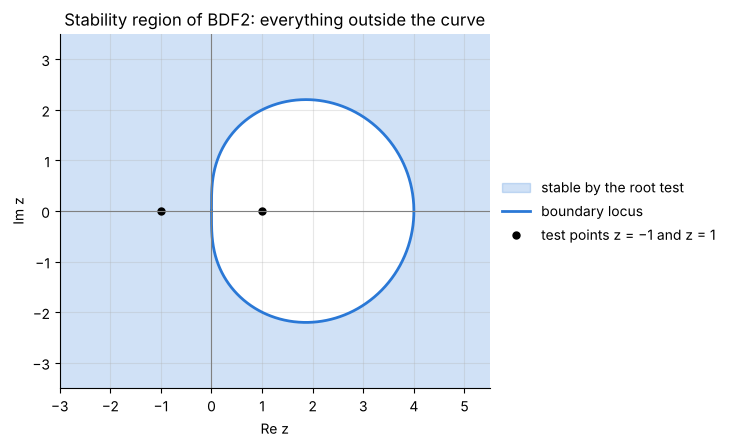

In [6]:
theta = np.linspace(0, 2 * np.pi, 1441)
zeta = np.exp(1j * theta)
locus = 3 / 2 - 2 / zeta + 1 / (2 * zeta**2)

def bdf2_roots(z):
    """Moduli of the two roots ζ of (3/2 - z) ζ² - 2ζ + 1/2 = 0."""
    return np.abs(np.roots([3 / 2 - z, -2, 1 / 2]))

print(f"locus at θ = 0: z = {locus[0].real:.3f};  at θ = π: z = {locus[720].real:.3f}")
print(f"root test:  z = -1: |ζ| = {bdf2_roots(-1).round(4)}   z = 1: |ζ| = {bdf2_roots(1).round(4)}")
print("   z          larger |ζ|     |ζ| √(2|z|)     trapezoidal |R(z)|")
for z in (-1e2, -1e4, -1e6):
    print(f"{z:9.0e} {bdf2_roots(z).max():13.6f} {bdf2_roots(z).max() * np.sqrt(2 * abs(z)):13.4f} {abs((1 + z / 2) / (1 - z / 2)):17.6f}")

re, im = np.linspace(-3, 5.5, 340), np.linspace(-3.5, 3.5, 280)       # even counts keep the pole z = 3/2 off the grid
Z = re[None, :] + 1j * im[:, None]
root = np.sqrt(1 + 2 * Z)                                              # the two roots are (2 ± root)/(3 - 2z)
largest_root = np.maximum(np.abs((2 + root) / (3 - 2 * Z)), np.abs((2 - root) / (3 - 2 * Z)))
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.contourf(re, im, largest_root, levels=[0, 1], colors=[BLUE], alpha=0.22)
ax.fill([], [], color=BLUE, alpha=0.22, label="stable by the root test")
ax.plot(locus.real, locus.imag, color=BLUE, label="boundary locus")
ax.plot([-1, 1], [0, 0], "ko", ms=5, label="test points z = −1 and z = 1")
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="0.5", lw=0.8)
ax.set(title="Stability region of BDF2: everything outside the curve", xlabel="Re z", ylabel="Im z",
       xlim=(-3, 5.5), ylim=(-3.5, 3.5), aspect="equal")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

The last column of the table is the reason for the preference. For the stiffest modes the
trapezoidal rule has $|R| \to 1$: it does not damp them, it flips their sign at every step.
BDF2 multiplies them by a factor that tends to zero. A demonstration: the slab of 9.6 with
$N = 24$, started from the uniform temperature $u = 1$ with the surfaces suddenly held at
zero. This initial condition does not satisfy the boundary conditions, so it excites every mode
of the matrix. Take ten steps of $\Delta t = 0.02$, which is 114 times the RK4 limit. BDF2
needs one starting step, taken with backward Euler. The exact solution is the Fourier series
$u = \sum_{m\ge0}\frac{4(-1)^m}{(2m+1)\pi}\cos\frac{(2m+1)\pi x}{2}\,e^{-(2m+1)^2\pi^2t/4}$.

largest error at t = 0.2 after 10 steps:  trapezoidal rule 0.635   BDF2 0.0023


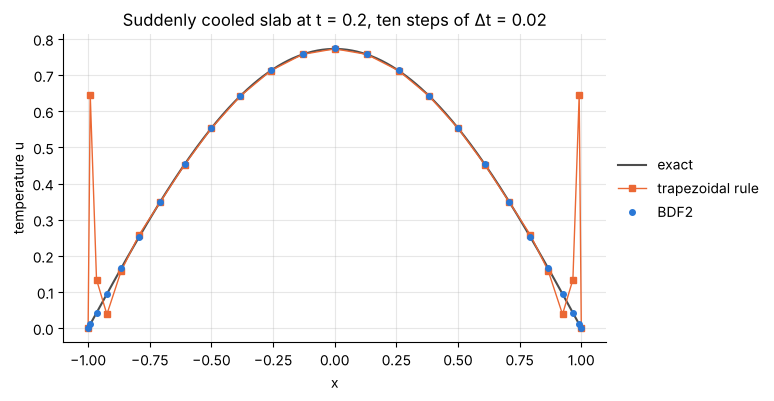

In [7]:
N = 24
D, x = cheb(N)
A, I = (D @ D)[1:-1, 1:-1], np.eye(N - 1)                    # interior unknowns; u = 0 at index 0 (x = 1) and index N (x = -1)
dt, n_steps = 0.02, 10

def quench_exact(x, t, n_modes=200):
    m = np.arange(n_modes)[:, None]
    return np.sum(4 * (-1.0) ** m / ((2 * m + 1) * np.pi) * np.cos((2 * m + 1) * np.pi * x / 2)
                  * np.exp(-((2 * m + 1) ** 2) * np.pi**2 * t / 4), axis=0)

u_trap = np.ones(N - 1)
factors = lu_factor(I - dt / 2 * A)
for _ in range(n_steps):
    u_trap = lu_solve(factors, (I + dt / 2 * A) @ u_trap)

old, new = np.ones(N - 1), np.linalg.solve(I - dt * A, np.ones(N - 1))       # starting step: backward Euler
factors = lu_factor(3 / 2 * I - dt * A)
for _ in range(n_steps - 1):
    old, new = new, lu_solve(factors, 2 * new - old / 2)                     # (3/2 I - Δt A) u^{n+1} = 2 u^n - u^{n-1}/2
u_bdf2 = new

exact = quench_exact(x[1:-1], dt * n_steps)
error_trap, error_bdf2 = np.abs(u_trap - exact).max(), np.abs(u_bdf2 - exact).max()
print(f"largest error at t = {dt * n_steps:.1f} after {n_steps} steps:  trapezoidal rule {error_trap:.3f}   BDF2 {error_bdf2:.4f}")

fine = np.linspace(-1, 1, 401)
with_walls = lambda u: np.concatenate([[0.0], u, [0.0]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fine, quench_exact(fine, dt * n_steps), color="0.3", lw=1.5, label="exact")
ax.plot(x, with_walls(u_trap), "s-", ms=4, lw=1, color=ORANGE, label="trapezoidal rule")
ax.plot(x, with_walls(u_bdf2), "o", ms=4, color=BLUE, label="BDF2")
ax.set(xlabel="x", ylabel="temperature u", title="Suddenly cooled slab at t = 0.2, ten steps of Δt = 0.02")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [8]:
# verify: the crossings, the root test on both sides, the limit of the roots, and the demonstration
assert abs(locus[0]) < 1e-14 and abs(locus[720] - 4) < 1e-12
assert locus.real.min() > -1e-12                                           # the curve never enters the left half-plane
assert bdf2_roots(-1).max() < 1 < bdf2_roots(1).max()
assert np.allclose(bdf2_roots(-1), 1 / np.sqrt(5))                         # by hand: 5ζ² - 4ζ + 1 = 0, |ζ|² = 1/5
assert abs(bdf2_roots(-1e6).max() * np.sqrt(2e6) - 1) < 1e-5
assert error_bdf2 < 5e-3 and error_trap > 0.3

**Answer.** The locus is a closed curve in the right half-plane through $z = 0$ and $z = 4$.
At $z = -1$ both roots have $|\zeta| = 0.447$ and at $z = 1$ one root is $3.73$, so BDF2 is
stable **outside** the curve, which includes the whole left half-plane. As $z \to -\infty$ the
larger root behaves as $1/\sqrt{2|z|}$ and tends to zero: 0.0007 at $z = -10^6$, where the
trapezoidal rule has $|R| = 0.999996$.

That is why BDF2 is preferred for rough data. Both formulas are second-order accurate and
stable for any step, but in the quenched slab the trapezoidal rule is left after ten steps
with an error of 0.64 in a temperature of order one, a sawtooth at the walls that is the
undamped grid modes, while BDF2 is accurate to 0.002. Stable is not the same as damped.

## Exercise 3

Solve $u_t + u_x = 0$ on $[-1, 1]$ with the inflow condition $u(-1, t) = 0$, the initial
pulse $u(x, 0) = e^{-40(x + 0.3)^2}$, Chebyshev points with $N = 48$ and RK4, up to $t = 0.8$.
(The wave moves to the right, so the boundary value is prescribed at index $N$.) Compute the
largest stable RK4 step from the eigenvalues, run at 0.9 and 1.2 times that step, and
compare the stable run with the exact solution $e^{-40(x - t + 0.3)^2}$.

The unknowns are the values at indices $0, \dots, N-1$; index $N$ is $x = -1$, where $u = 0$,
so the last row and column of $D$ are deleted and the system is
$\mathbf{u}' = -D_{[0:N,\,0:N]}\,\mathbf{u}$. No condition is imposed at the outflow end
$x = +1$ (index 0): the pulse leaves through it. By the symmetry $x \to -x$ this matrix has the
same eigenvalues as the one in 9.3, of size $0.089N^2$. The exact solution is not exactly zero
at $x = -1$, but it is below $e^{-40\times0.49} = 3\times10^{-9}$ there, which sets the floor
for the comparison.

largest |λ| = 205.0 = 0.0890 N²;  largest stable RK4 step: Δt = 0.01412
0.9 × limit: 63 steps, largest error at t = 0.8: 5.7e-05
1.2 × limit: 48 steps, max |u| at t = 0.8: 4.3e+12
0.1 × limit: largest error 3.8e-07


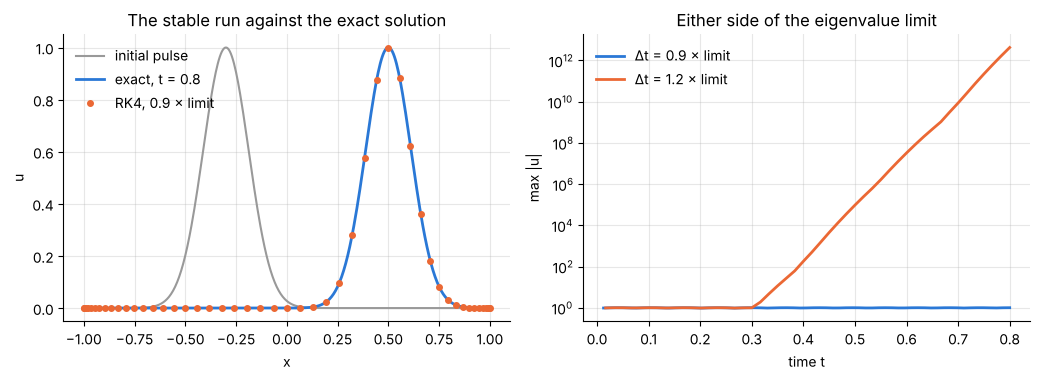

In [9]:
N, t_end = 48, 0.8
D, x_all = cheb(N)
A, x = -D[:N, :N], x_all[:N]                                # index N (x = -1, the inflow end) removed
pulse_exact = lambda x, t: np.exp(-40 * (x - t + 0.3) ** 2)

eigenvalues = np.linalg.eigvals(A)
dt_limit = largest_stable_step(eigenvalues, R["RK4"])
print(f"largest |λ| = {np.abs(eigenvalues).max():.1f} = {np.abs(eigenvalues).max() / N**2:.4f} N²;  largest stable RK4 step: Δt = {dt_limit:.5f}")

def advect_chebyshev(dt_target):
    """RK4 to t_end with a step close to dt_target; returns the final state, the times and the history of max |u|."""
    n = int(np.ceil(t_end / dt_target))
    dt, u, size = t_end / n, pulse_exact(x, 0), []
    for _ in range(n):
        u = rk4_step(lambda v: A @ v, u, dt)
        size.append(np.abs(u).max())
    return u, dt * np.arange(1, n + 1), np.array(size)

runs = {factor: advect_chebyshev(factor * dt_limit) for factor in (0.9, 1.2)}
u_small = advect_chebyshev(dt_limit / 10)[0]
error_stable = np.abs(runs[0.9][0] - pulse_exact(x, t_end)).max()
error_small = np.abs(u_small - pulse_exact(x, t_end)).max()
print(f"0.9 × limit: {len(runs[0.9][1])} steps, largest error at t = {t_end}: {error_stable:.1e}")
print(f"1.2 × limit: {len(runs[1.2][1])} steps, max |u| at t = {t_end}: {runs[1.2][2][-1]:.1e}")
print(f"0.1 × limit: largest error {error_small:.1e}")

fine = np.linspace(-1, 1, 401)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].plot(fine, pulse_exact(fine, 0), color="0.6", lw=1.5, label="initial pulse")
axes[0].plot(fine, pulse_exact(fine, t_end), color=BLUE, label=f"exact, t = {t_end}")
axes[0].plot(x_all, np.append(runs[0.9][0], 0.0), "o", ms=4, color=ORANGE, label="RK4, 0.9 × limit")
axes[0].set(xlabel="x", ylabel="u", title="The stable run against the exact solution")
axes[0].legend(frameon=False, loc="upper left")
for factor, colour in ((0.9, BLUE), (1.2, ORANGE)):
    axes[1].semilogy(runs[factor][1], runs[factor][2], color=colour, label=f"Δt = {factor} × limit")
axes[1].set(xlabel="time t", ylabel="max |u|", title="Either side of the eigenvalue limit")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()

In [10]:
# verify: the size of the eigenvalues, both stability statements, and the accuracy against the exact solution
assert abs(np.abs(eigenvalues).max() / N**2 / 0.089 - 1) < 0.05 and eigenvalues.real.max() < 0
assert runs[0.9][2].max() < 1.001 and runs[1.2][2][-1] > 1e6
assert error_stable < 1e-4 and error_small < 1e-6
assert abs(x[np.argmax(runs[0.9][0])] - 0.5) < 0.05                       # the peak has moved from -0.3 to 0.5

**Answer.** The largest eigenvalue has modulus $205 = 0.089N^2$ and the RK4 limit is
$\Delta t = 0.0141$. At 0.9 times the limit (63 steps) the run is stable and agrees with the
exact solution to $6\times10^{-5}$; that error is the time-stepping error, since a step ten
times smaller brings it down to $4\times10^{-7}$, the resolution of the pulse with $N = 48$.
At 1.2 times the limit (48 steps) the solution reaches $4\times10^{12}$. The eigenvalue rule
located the limit correctly here, even though this matrix is far from normal. Note the price
of the Chebyshev grid for a wave problem: 63 steps for a pulse that travels a distance of 0.8
on a grid of 49 points, because the step is set by the $O(N^{-2})$ spacing at the walls.

## Exercise 4

Repeat the cooling problem of 9.6 with $N = 48$. By what factor does the RK4 step limit
change, and how many RK4 steps are now needed to reach $t = 1$? Run the trapezoidal rule
with 50, 100, 200 and 400 steps, confirm that its error at $t = 1$ falls as $\Delta t^2$,
and state how many steps give a relative error below $10^{-5}$.

The largest eigenvalue of the Chebyshev second-derivative matrix grows as $0.048N^4$, so
doubling $N$ should divide the RK4 limit by about 16. The trapezoidal rule is second-order
accurate, so its error should fall by 4 for each doubling of the number of steps, and one
measured error fixes the constant: the step count for a given tolerance follows from
$\text{error} \approx C/n^2$.

RK4 step limit:  N = 24: 1.755e-04   N = 48: 1.105e-05   ratio 15.88
RK4 steps to reach t = 1 with N = 48: at least 90491; at 0.95 × limit, 95254

trapezoidal rule:  steps    relative error at t = 1
                     50         5.008e-04
                    100         1.252e-04
                    200         3.130e-05
                    400         7.824e-06
measured order: 2.0001
steps for a relative error below 1e-5: predicted 353.8, found 354


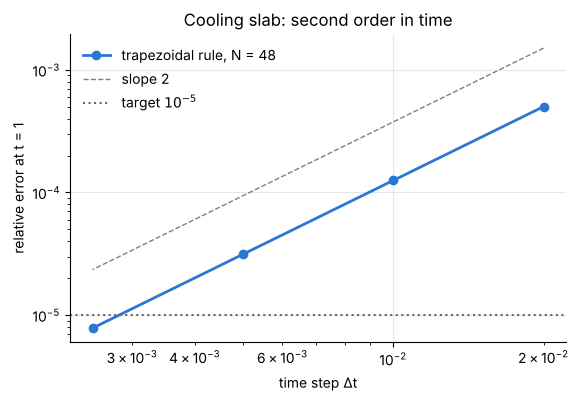

In [11]:
slab_exact = lambda x, t: (np.exp(-np.pi**2 * t / 4) * np.cos(np.pi * x / 2)
                           + 0.25 * np.exp(-9 * np.pi**2 * t / 4) * np.cos(3 * np.pi * x / 2))

def slab_matrix(N):
    """Interior second-derivative matrix and interior points; u = 0 at index 0 (x = 1) and index N (x = -1)."""
    D, x = cheb(N)
    return (D @ D)[1:-1, 1:-1], x[1:-1]

rk4_limit = {N: largest_stable_step(np.linalg.eigvals(slab_matrix(N)[0]), R["RK4"]) for N in (24, 48)}
print(f"RK4 step limit:  N = 24: {rk4_limit[24]:.3e}   N = 48: {rk4_limit[48]:.3e}   ratio {rk4_limit[24] / rk4_limit[48]:.2f}")
print(f"RK4 steps to reach t = 1 with N = 48: at least {int(np.ceil(1 / rk4_limit[48]))}; at 0.95 × limit, {int(np.ceil(1 / (0.95 * rk4_limit[48])))}")

A, x = slab_matrix(48)
scale = np.abs(slab_exact(x, 1.0)).max()

def trapezoidal_error(n):
    """Relative error at t = 1 of the trapezoidal rule (Crank-Nicolson) with n equal steps."""
    dt, u, I = 1.0 / n, slab_exact(x, 0), np.eye(len(x))
    factors, right = lu_factor(I - dt / 2 * A), I + dt / 2 * A
    for _ in range(n):
        u = lu_solve(factors, right @ u)
    return np.abs(u - slab_exact(x, 1.0)).max() / scale

steps = np.array([50, 100, 200, 400])
errors = np.array([trapezoidal_error(n) for n in steps])
order = -np.polyfit(np.log(steps), np.log(errors), 1)[0]
print("\ntrapezoidal rule:  steps    relative error at t = 1")
for n, error in zip(steps, errors):
    print(f"{n:23d} {error:17.3e}")
print(f"measured order: {order:.4f}")

n_predicted = steps[0] * np.sqrt(errors[0] / 1e-5)                      # from error = C/n²
n_needed = int(np.floor(n_predicted)) - 3
while trapezoidal_error(n_needed) >= 1e-5:
    n_needed += 1
print(f"steps for a relative error below 1e-5: predicted {n_predicted:.1f}, found {n_needed}")

fig, ax = plt.subplots()
ax.loglog(1 / steps, errors, "o-", label="trapezoidal rule, N = 48")
ax.loglog(1 / steps, 3 * errors[0] * (steps[0] / steps) ** 2.0, "--", color="0.5", lw=1, label="slope 2")
ax.axhline(1e-5, color="0.4", ls=":", lw=1.5, label="target $10^{-5}$")
ax.set(xlabel="time step Δt", ylabel="relative error at t = 1", title="Cooling slab: second order in time")
ax.legend(frameon=False, loc="upper left");

In [12]:
# verify: the N⁴ scaling, the order, the sharpness of the step count, and an RK4 run just inside the new limit
assert abs(rk4_limit[24] / rk4_limit[48] / 16 - 1) < 0.05
assert abs(order - 2) < 0.01
assert trapezoidal_error(n_needed) < 1e-5 <= trapezoidal_error(n_needed - 1) and abs(n_needed - n_predicted) < 2

n_rk4 = int(np.ceil(1 / (0.95 * rk4_limit[48])))
u = slab_exact(x, 0)
for _ in range(n_rk4):
    u = rk4_step(lambda v: A @ v, u, 1.0 / n_rk4)
rk4_error = np.abs(u - slab_exact(x, 1.0)).max() / scale
print(f"RK4 with {n_rk4} steps: relative error at t = 1: {rk4_error:.1e}")
assert rk4_error < 1e-10

RK4 with 95254 steps: relative error at t = 1: 8.1e-14


**Answer.** The RK4 limit falls from $1.755\times10^{-4}$ to $1.105\times10^{-5}$, a factor of
15.9, as the $N^4$ law predicts. RK4 now needs at least 90 491 steps to reach $t = 1$ (95 254
at 0.95 of the limit, where it is stable and accurate to $10^{-13}$), against 5998 for $N = 24$.
The trapezoidal errors are $5.0\times10^{-4}$, $1.3\times10^{-4}$, $3.1\times10^{-5}$ and
$7.8\times10^{-6}$: a factor of four for each halving of the step, measured order 2.000. A
relative error below $10^{-5}$ needs 354 steps (400 among the four runs), each about 256 times longer
than the RK4 limit. The trapezoidal step count does not depend on $N$ at all: it is set by
the physics of the cooling, where the explicit count is set by the grid.

## Exercise 5

In the cable problem of 9.7 make the heavy section sixteen times heavier, so that the
minimum wave speed is $\tfrac14$: $c(x) = 1 - \tfrac34\exp(-8(1 - \cos(x - 3.6)))$. Predict the
position of the transmitted pulse at $t = 5.5$ from the travel-time integral and compare it
with the leapfrog solution ($N = 256$, half the limiting step). How large is the reflected pulse
now, and is the energy still conserved to $10^{-4}$?

The code of 9.7 is collected in one function with the depth of the dip in wave speed as a
parameter, so that the original cable (depth $\tfrac12$, $t = 4.5$) can be run next to the new
one (depth $\tfrac34$, $t = 5.5$). The largest wave speed is still 1, so the leapfrog limit
$\Delta t = 1/(c_{\max}N/2)$ is unchanged. The pulse spends longer in the heavy section, which
is why the end time is later.

In [13]:
def cable(depth, t_end, step_fraction=0.5, N=256, x_start=1.2):
    """Leapfrog solution of u_tt = c² u_xx on the ring with c = 1 - depth exp(-8 (1 - cos(x - 3.6)))."""
    x = 2 * np.pi * np.arange(N) / N
    speed = lambda x: 1 - depth * np.exp(-8 * (1 - np.cos(x - 3.6)))
    c = speed(x)
    u0 = np.exp(-((x - x_start) / 0.15) ** 2)
    v0 = -fft_derivative(u0)                                     # a right-moving pulse where c = 1: u_t = -u_x
    rhs = lambda w: np.array([w[1], c**2 * fft_derivative(w[0], 2)])
    energy_of = lambda w: 0.5 * np.sum(w[1] ** 2 / c**2 + fft_derivative(w[0]) ** 2) * 2 * np.pi / N

    n = int(np.ceil(t_end / (step_fraction / (c.max() * N / 2))))
    dt = t_end / n
    old = np.array([u0, v0])
    new = rk4_step(rhs, old, dt)                                 # starting step
    energy, snapshots = [energy_of(old), energy_of(new)], [u0, new[0]]
    for _ in range(n - 1):
        old, new = new, old + 2 * dt * rhs(new)
        energy.append(energy_of(new))
        snapshots.append(new[0])

    # predicted position: invert the travel time, integrated on a fine grid with the trapezoidal rule
    s = np.linspace(x_start, 2 * np.pi, 200001)
    travel_time = np.concatenate([[0], np.cumsum((1 / speed(s[1:]) + 1 / speed(s[:-1])) / 2 * np.diff(s))])
    # measured position: the peak of the trigonometric interpolant on a grid 16 times finer
    padded = np.zeros(16 * N, dtype=complex)
    u_hat = np.fft.fft(new[0])
    padded[:N // 2], padded[-N // 2:] = u_hat[:N // 2], u_hat[N // 2:]
    u_fine = 16 * np.real(np.fft.ifft(padded))
    x_fine = 2 * np.pi * np.arange(16 * N) / (16 * N)
    x_measured = x_fine[np.argmax(u_fine)]
    # the reflected pulse is the deepest point more than 1 away from the transmitted peak (distance round the ring);
    # the wake is the deepest point within 1 behind the peak
    away = np.abs((x_fine - x_measured + np.pi) % (2 * np.pi) - np.pi) > 1.0
    behind = (x_fine > x_measured - 1.0) & (x_fine < x_measured)
    return {"x": x, "c": c, "dt": dt, "steps": n, "snapshots": np.array(snapshots), "s": s, "travel_time": travel_time,
            "x_predicted": np.interp(t_end, travel_time, s), "x_measured": x_measured,
            "energy_change": np.abs(np.array(energy) / energy[0] - 1).max(),
            "x_fine": x_fine, "u_fine": u_fine, "height": u_fine.max(), "reflected": u_fine[away].min(),
            "wake": u_fine[behind].min(), "steepest": fft_derivative(c).min()}

t_end = 5.5
heavy = cable(0.75, t_end)
original = cable(0.5, 4.5)
print(f"leapfrog: Δt = {heavy['dt']:.5f}, {heavy['steps']} steps")
print(f"pulse position at t = {t_end}:  measured {heavy['x_measured']:.4f}   predicted {heavy['x_predicted']:.4f}   (at unit speed it would be {1.2 + t_end:.1f})")
print(f"largest relative change of the energy: {heavy['energy_change']:.1e}")
print(f"reflected pulse height: {heavy['reflected']:.4f}   (cable of 9.7: {original['reflected']:.4f})")
print(f"transmitted pulse height: {heavy['height']:.3f}, wake behind it: {heavy['wake']:.3f}   (cable of 9.7: {original['height']:.3f} and {original['wake']:.3f})")

leapfrog: Δt = 0.00391, 1408 steps
pulse position at t = 5.5:  measured 5.0038   predicted 4.9971   (at unit speed it would be 6.7)
largest relative change of the energy: 1.8e-05
reflected pulse height: -0.0806   (cable of 9.7: -0.0548)
transmitted pulse height: 0.942, wake behind it: -0.077   (cable of 9.7: 0.985 and -0.022)


For the size of the reflection there is an estimate to compare with. A small step in wave
speed from $c$ to $c + dc$ reflects the fraction $dc/(2c)$ of the displacement (the limit of
the formula $(c_2 - c_1)/(c_2 + c_1)$ for a sharp junction). Adding up the echoes from every
part of a gradual change, for a pulse that is short compared with the length of the change
and neglecting echoes of echoes, gives a reflected signal

$$u_{\text{reflected}} \approx \tfrac14\,c'(x)\int u_{\text{incident}}\,dx ,$$

where $x$ is the place the echo comes from. The reflection is strongest from where the wave
speed falls most steeply, and the area of the incident pulse is $0.15\sqrt\pi$. This is a
first-order estimate, good to several per cent while the reflection is weak.

with half the time step: position 5.0008, reflected height -0.0806, energy change 7.2e-06
reflected height one time unit earlier, at t = 4.5: -0.0806
depth 1/2: reflected height -0.0548, weak-reflection estimate -0.0561
depth 3/4: reflected height -0.0806, weak-reflection estimate -0.0841


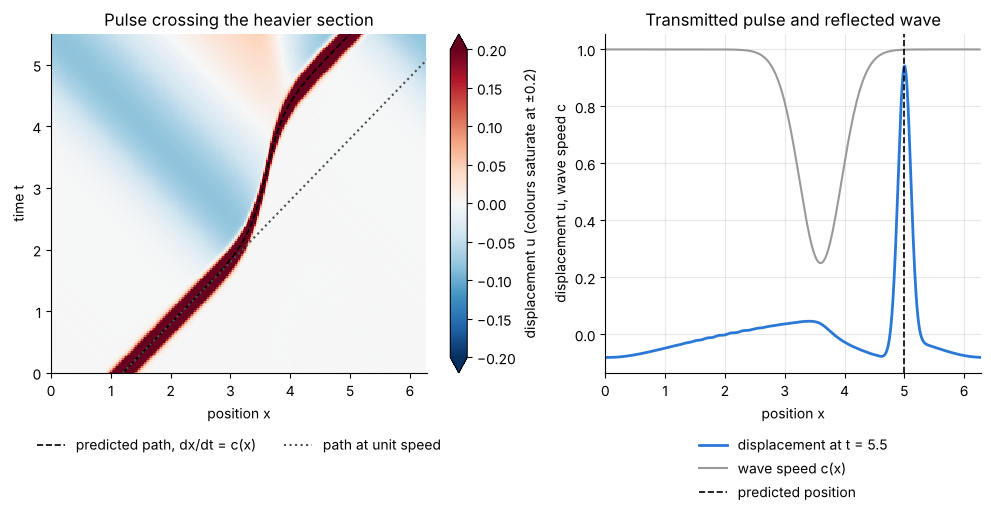

In [14]:
# verify: travel time, energy, a run with half the time step, and the weak-reflection estimate for both cables
assert abs(heavy["x_measured"] - heavy["x_predicted"]) < 0.01 and 1.2 + t_end - heavy["x_measured"] > 1.5
assert heavy["energy_change"] < 1e-4
finer = cable(0.75, t_end, step_fraction=0.25)
print(f"with half the time step: position {finer['x_measured']:.4f}, reflected height {finer['reflected']:.4f}, energy change {finer['energy_change']:.1e}")
assert abs(finer["x_measured"] - heavy["x_measured"]) < 0.005 and abs(finer["reflected"] - heavy["reflected"]) < 1e-3
earlier = cable(0.75, 4.5)                                       # the reflected pulse keeps its height as it travels
print(f"reflected height one time unit earlier, at t = 4.5: {earlier['reflected']:.4f}")
assert abs(earlier["reflected"] - heavy["reflected"]) < 1e-4
assert abs(finer["x_measured"] - heavy["x_predicted"]) < abs(heavy["x_measured"] - heavy["x_predicted"])
for run, name in ((original, "depth 1/2"), (heavy, "depth 3/4")):
    estimate = 0.25 * run["steepest"] * 0.15 * np.sqrt(np.pi)
    print(f"{name}: reflected height {run['reflected']:.4f}, weak-reflection estimate {estimate:.4f}")
    assert abs(run["reflected"] / estimate - 1) < 0.1

every = 8
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
image = axes[0].pcolormesh(heavy["x"], heavy["dt"] * np.arange(0, heavy["steps"] + 1, every), heavy["snapshots"][::every],
                           cmap="RdBu_r", vmin=-0.2, vmax=0.2, shading="auto")
inside = heavy["travel_time"] <= t_end
axes[0].plot(heavy["s"][inside], heavy["travel_time"][inside], "k--", lw=1.2, label="predicted path, dx/dt = c(x)")
axes[0].plot([1.2, 2 * np.pi], [0, 2 * np.pi - 1.2], ":", color="0.3", lw=1.5, label="path at unit speed")
axes[0].set(xlabel="position x", ylabel="time t", xlim=(0, 2 * np.pi), ylim=(0, t_end), title="Pulse crossing the heavier section")
axes[0].grid(False)
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.colorbar(image, ax=axes[0], label="displacement u (colours saturate at ±0.2)", extend="both")
axes[1].plot(heavy["x_fine"], heavy["u_fine"], label=f"displacement at t = {t_end}")
axes[1].plot(heavy["x"], heavy["c"], color="0.6", lw=1.5, label="wave speed c(x)")
axes[1].axvline(heavy["x_predicted"], color="k", ls="--", lw=1.2, label="predicted position")
axes[1].set(xlabel="position x", ylabel="displacement u, wave speed c", title="Transmitted pulse and reflected wave", xlim=(0, 2 * np.pi))
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1);

**Answer.** The travel-time integral puts the pulse at $x = 4.997$ at $t = 5.5$ and the leapfrog
solution has its peak at $x = 5.004$: it is 1.70 behind where it would be at unit speed, and
within 0.007 of the prediction (0.004 with half the time step, so part of the difference is
the phase error of leapfrog). The energy changes by at most $1.8\times10^{-5}$, the same as in
9.7 and inside $10^{-4}$: the time step is unchanged because the largest wave speed is.

The reflected pulse has height $-0.081$, eight per cent of the incident pulse, against $-0.055$
in 9.7. It grows almost in proportion to the depth of the dip, as the estimate
$\tfrac14c'\!\int u\,dx$ predicts ($-0.084$ and $-0.056$). A sharp junction to a cable sixteen
times heavier would reflect $(\tfrac14 - 1)/(\tfrac14 + 1) = -0.6$ of the pulse: a gradual change
of wave speed reflects far less than an abrupt one, which is why transitions in transmission
lines and acoustic horns are tapered.

Two features of the figure are worth a second look. The transmitted pulse leaves the heavy
section lower (height 0.942) and with a negative wake behind it of depth $-0.077$ (the blue
streak that follows it in the left panel), almost as deep as the reflected pulse, so it is no
longer a copy of the pulse that went in. In 9.7 the wake was only $-0.022$. And the ring is closed: the
reflected wave, travelling to the left, has passed $x = 0$ and by $t = 5.5$ its front is
arriving at the transmitted pulse from the other side (the blue region at the top right). Its
height is the same at $t = 4.5$ and at $t = 5.5$, so the value quoted is not affected, but a
much later end time would mix the two.